# ТК 5-6 (ПР3): kNN — качество красного вина
Протокол workbook: один стратифицированный сплит 70/30, `KNeighborsClassifier(k=5)`. Оригиналы лежат в `docs/` и не меняются. `random_state=42` — отклонение от workbook (там сид не задан), нужно для воспроизводимости.

In [1]:
import sys
sys.path.insert(0, '.')
from wine_knn import load_wine_data, evaluate_knn, k_sweep
CSV = 'docs/winequality-red.csv'
df, info = load_wine_data(CSV)
print(info)
print(df.dtypes)
print(df.describe().T)

{'shape': (1599, 12), 'missing_cells': 0, 'full_dup_rows': 240, 'quality_counts': {3: 10, 4: 53, 5: 681, 6: 638, 7: 199, 8: 18}}
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object
                       count       mean        std      min      25%  \
fixed acidity         1599.0   8.319637   1.741096  4.60000   7.1000   
volatile acidity      1599.0   0.527821   0.179060  0.12000   0.3900   
citric acid           1599.0   0.270976   0.194801  0.00000   0.0900   
residual sugar        1599.0   2.538806   1.409928  0.90000   1.9000   
chlorides             1599.0   0.087467   0.047065  0.01200   0.0700   
free sulfur dioxide   1599.0  15.874922  

In [2]:
res = evaluate_knn(CSV)
print('test_n:', res['test_size'])
print('train_acc:', round(res['train_accuracy'],4), 'test_acc:', round(res['accuracy'],4))
for k in ('precision_macro','recall_macro','f1_macro','precision_weighted','recall_weighted','f1_weighted','roc_auc_ovr_macro','roc_auc_ovr_weighted'):
    print(k, round(res[k],4))
for m in ('precision','recall','f1'):
    print('per-class ' + m + ':', {k: round(v,3) for k,v in res['per_class'][m].items()})
print('support_test:', res['per_class']['support_test'])
print('per-class ROC AUC:', {k: round(v,3) for k,v in res['per_class']['roc_auc_ovr'].items()})
print('confusion_matrix:\n', res['confusion_matrix'])

test_n: 480
train_acc: 0.6372 test_acc: 0.4896
precision_macro 0.2241
recall_macro 0.2186
f1_macro 0.2166
precision_weighted 0.4566
recall_weighted 0.4896
f1_weighted 0.4684
roc_auc_ovr_macro 0.6173
roc_auc_ovr_weighted 0.6521
per-class precision: {3: 0.0, 4: 0.0, 5: 0.53, 6: 0.471, 7: 0.344, 8: 0.0}
per-class recall: {3: 0.0, 4: 0.0, 5: 0.613, 6: 0.516, 7: 0.183, 8: 0.0}
per-class f1: {3: 0.0, 4: 0.0, 5: 0.568, 6: 0.493, 7: 0.239, 8: 0.0}
support_test: {3: 3, 4: 16, 5: 204, 6: 192, 7: 60, 8: 5}
per-class ROC AUC: {3: 0.486, 4: 0.519, 5: 0.689, 6: 0.603, 7: 0.725, 8: 0.682}
confusion_matrix:
 [[  0   0   1   2   0   0]
 [  0   0  11   5   0   0]
 [  0   1 125  71   7   0]
 [  0   0  81  99  12   0]
 [  0   1  18  30  11   0]
 [  0   0   0   3   2   0]]


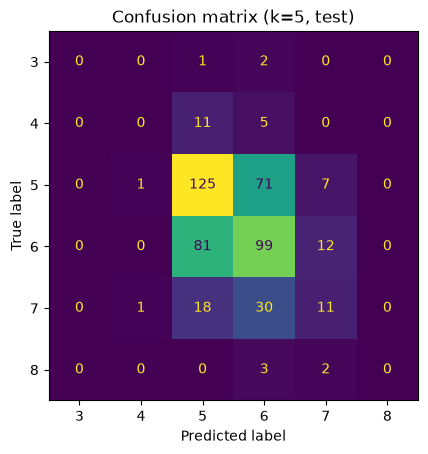

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
disp = ConfusionMatrixDisplay(res['confusion_matrix'], display_labels=res['classes'])
disp.plot(colorbar=False)
plt.title('Confusion matrix (k=5, test)'); plt.show()

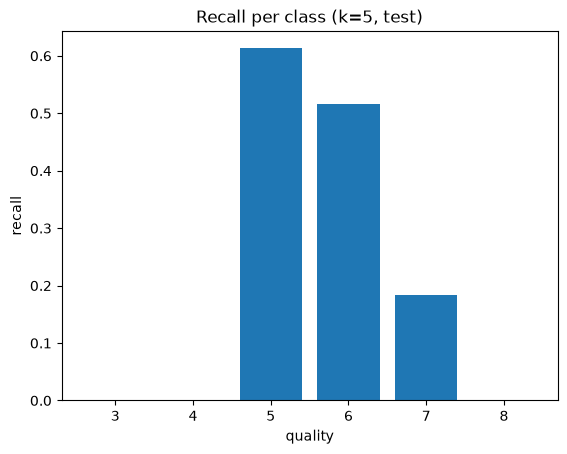

In [4]:
import matplotlib.pyplot as plt
rc = res['per_class']['recall']
plt.bar(list(rc.keys()), list(rc.values()))
plt.xlabel('quality'); plt.ylabel('recall')
plt.title('Recall per class (k=5, test)'); plt.show()

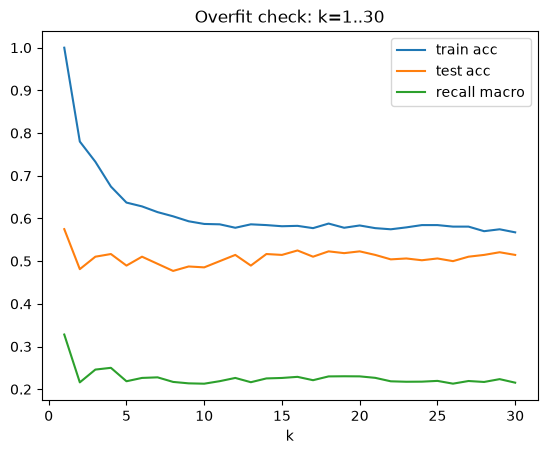

In [5]:
rows = k_sweep(CSV)
k_values=[row['k'] for row in rows]
train_acc=[row['train_accuracy'] for row in rows]
test_acc=[row['test_accuracy'] for row in rows]
recall_macro=[row['recall_macro'] for row in rows]
import matplotlib.pyplot as plt
plt.plot(k_values, train_acc, label='train acc'); plt.plot(k_values, test_acc, label='test acc'); plt.plot(k_values, recall_macro, label='recall macro')
plt.xlabel('k'); plt.legend(); plt.title('Overfit check: k=1..30'); plt.show()

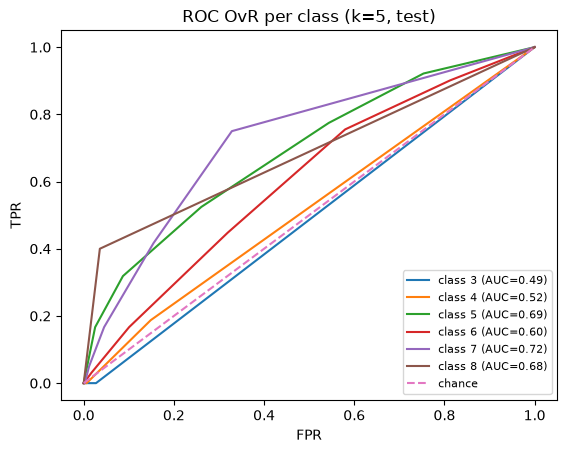

In [6]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import label_binarize
classes = res['classes']
y_binarized = label_binarize(res['y_test'], classes=classes)
fig, ax = plt.subplots()
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_binarized[:, i], res['y_proba'][:, i])
    ax.plot(fpr, tpr, label=f'class {cls} (AUC={res["per_class"]["roc_auc_ovr"][cls]:.2f})')
ax.plot([0,1],[0,1], linestyle='--', label='chance')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=8)
plt.title('ROC OvR per class (k=5, test)'); plt.show()

## Выводы
- kNN(k=5) без скейлинга: test accuracy ~0.49 при train ~0.64 — переобучение на малых k, разрыв виден на кривой k=1..30.
- Путаница в основном 5↔6 (мажоритарные классы); recall классов 3/4/8 ≈ 0 — в тесте их ~3/16/5 шт, kNN редкие классы не возвращает.
- Macro P/R/F1 ~0.22 против weighted ~0.46–0.49: расхождение — прямое следствие дисбаланса.
- OvR AUC macro ~0.62: ранжирование слабое; per-class AUC классов 3/8 нестабилен (малые выборки, см. Дьяконов про дисперсию AUC) — не использовать для ранжирования моделей.
- Масштабы признаков 0.01–289: для корректного kNN нужен StandardScaler (внутри Pipeline при CV); здесь осознанно оставлен протокол workbook без скейлинга.